# STEP 4 : Predict ด้วย weight ที่เทรนแล้ว
**ไฟล์คู่กัน:** `04_predict.py`

ให้โมเดลทายภาพในชุด test แล้วดูว่า **ทายถูกไหม**

In [1]:
# ===== ตั้งค่าเริ่มต้น (ทุก notebook ใช้เหมือนกัน) =====
import os, sys, json
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # กัน error OMP บน Windows

# notebook อยู่ใน final_dip/scripts/  ->  ย้ายไปทำงานที่ final_dip/ (path ทุกอย่างอ้างอิงจากที่นี่)
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
os.chdir(ROOT)
CLASSES = ["airplane", "boat", "car", "motorcycle"]
print("ทำงานที่:", ROOT)
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

model_rect = YOLO("weights/rect_best.pt")     # Rectangle (detect)
model_poly = YOLO("weights/poly_best.pt")     # Polygon (segment)
print("คลาสที่โมเดลรู้จัก:", model_rect.names)

ทำงานที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip


คลาสที่โมเดลรู้จัก: {0: 'airplane', 1: 'boat', 2: 'car', 3: 'motorcycle'}


## 4.1 ผลลัพธ์ของ YOLO มีอะไรบ้าง
- `boxes.xyxy` = กรอบ `[x1, y1, x2, y2]` (pixel)
- `boxes.conf` = ความมั่นใจ 0–1
- `boxes.cls` = เลขคลาส
- `masks.xy` = จุด polygon ของแต่ละวัตถุ (**มีเฉพาะโมเดล seg**)

In [2]:
path = "web/frontend/samples/boat_001.jpg"
r = model_rect.predict(path, imgsz=512, verbose=False)[0]
print("RECT")
print("  boxes.xyxy :", r.boxes.xyxy.round().tolist())
print("  boxes.conf :", r.boxes.conf.round(decimals=3).tolist())
print("  boxes.cls  :", r.boxes.cls.tolist(), "->", [r.names[int(c)] for c in r.boxes.cls])
print("  masks      :", r.masks)

r = model_poly.predict(path, imgsz=512, verbose=False)[0]
print("\nPOLY")
print("  boxes.conf :", r.boxes.conf.round(decimals=3).tolist())
print("  masks.xy   :", len(r.masks.xy), "วัตถุ, วัตถุแรกมี", len(r.masks.xy[0]), "จุด")
print("  5 จุดแรก   :", r.masks.xy[0][:5].round().tolist())

RECT
  boxes.xyxy : [[39.0, 42.0, 361.0, 370.0]]
  boxes.conf : [0.9459999799728394]
  boxes.cls  : [1.0] -> ['boat']
  masks      : None



POLY
  boxes.conf : [0.9589999914169312]
  masks.xy   : 1 วัตถุ, วัตถุแรกมี 402 จุด
  5 จุดแรก   : [[356.0, 246.0], [356.0, 246.0], [178.0, 146.0], [176.0, 151.0], [175.0, 151.0]]


## 4.2 วาดผลเทียบกัน (โค้ดวาดแบบเดียวกับ lab : `cv2.rectangle` / `cv2.polylines`)

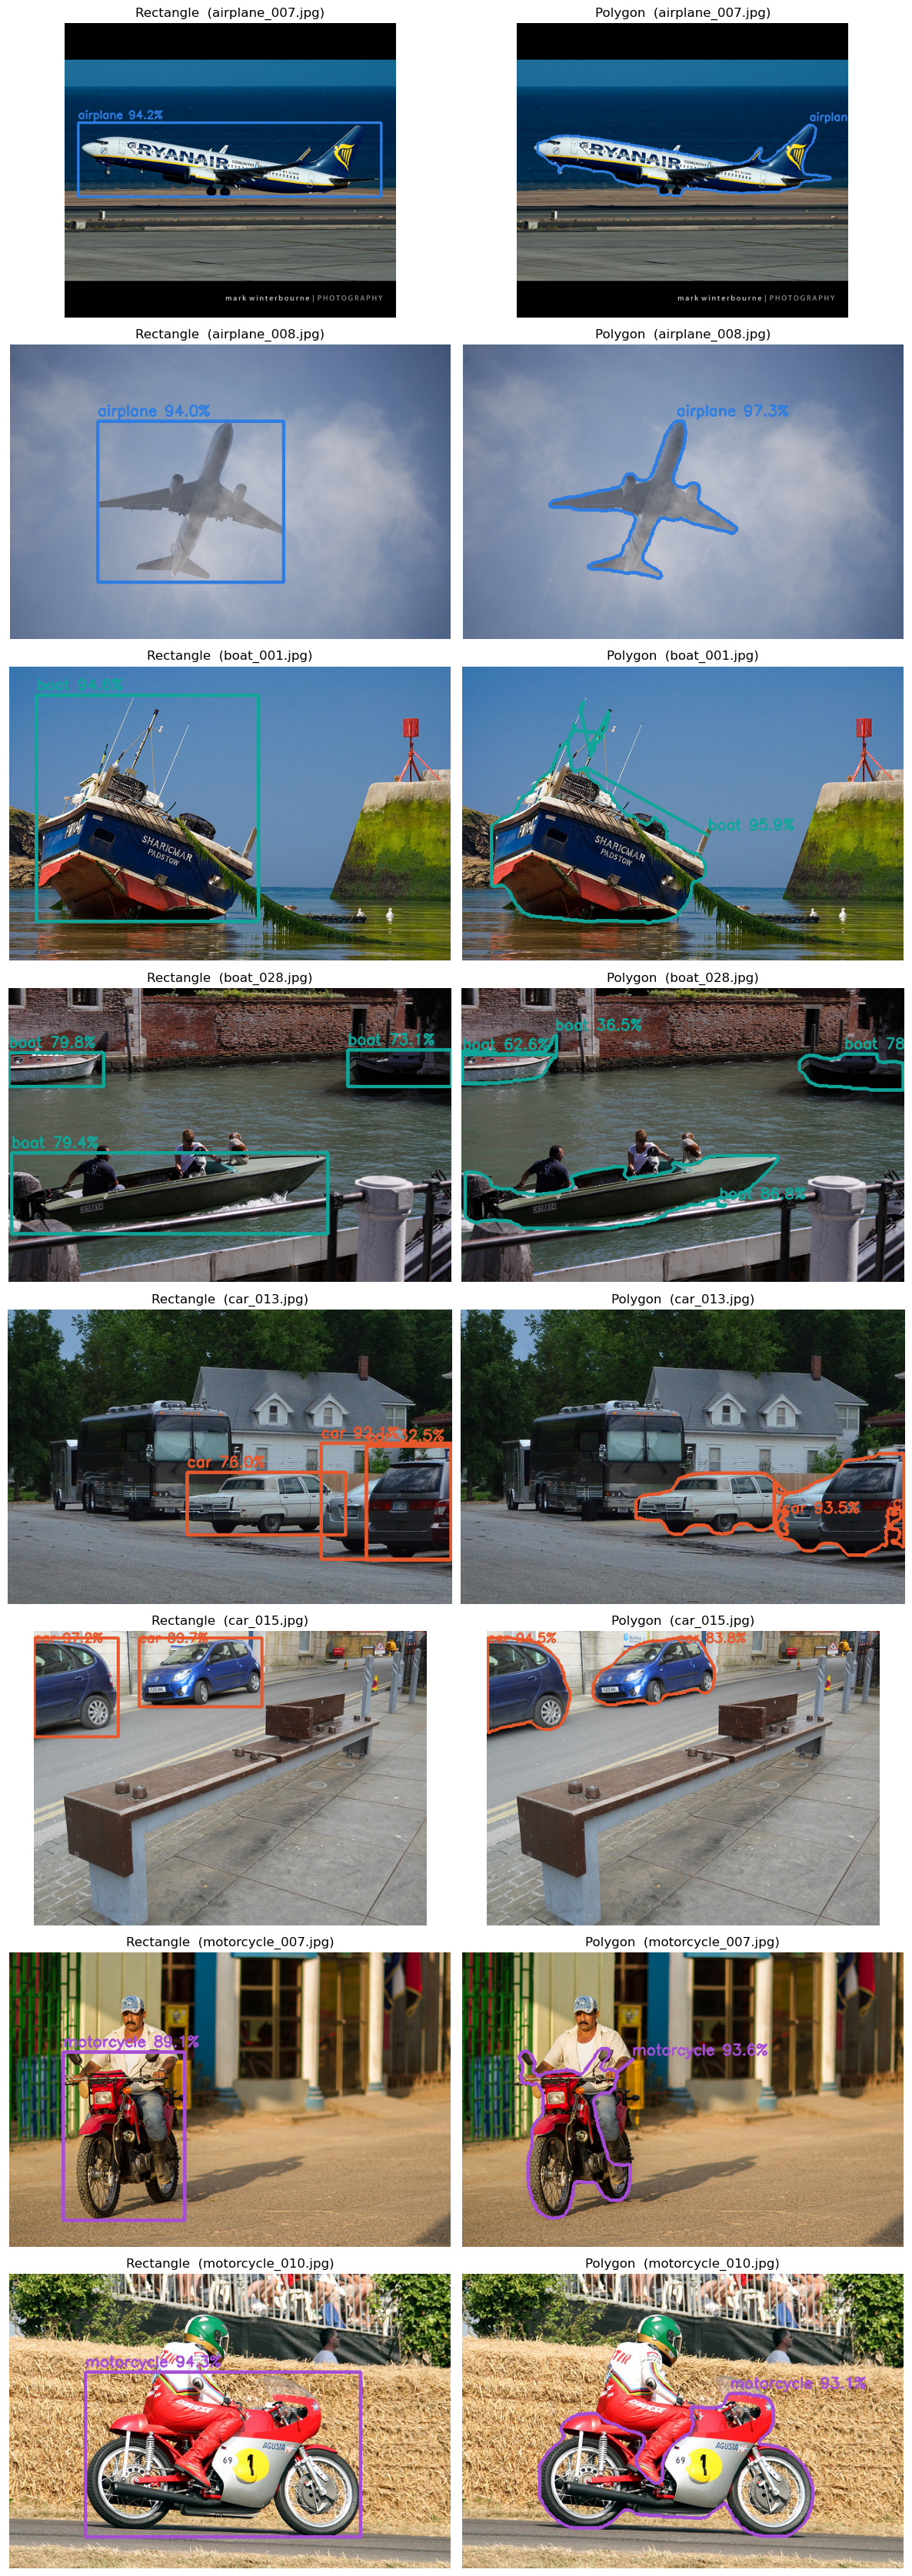

In [3]:
COLORS = {0: (47, 125, 225), 1: (17, 165, 154), 2: (232, 88, 45), 3: (166, 79, 214)}

def draw_rect(im_src, conf=0.25):
    result = model_rect.predict(source=im_src, imgsz=512, conf=conf, verbose=False)
    im = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)
    for box in result[0].boxes:
        cid = int(box.cls[0]); c = round(box.conf[0].item() * 100, 1)
        x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
        cv2.rectangle(im, (x1, y1), (x2, y2), COLORS[cid], 3)
        cv2.putText(im, f"{result[0].names[cid]} {c}%", (x1, max(y1 - 8, 18)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, COLORS[cid], 2)
    return im

def draw_poly(im_src, conf=0.25):
    result = model_poly.predict(source=im_src, imgsz=512, conf=conf, verbose=False)
    im = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)
    if result[0].masks is not None:
        for i in range(len(result[0].masks.xy)):
            cid = int(result[0].boxes.cls[i]); c = round(result[0].boxes.conf[i].item() * 100, 1)
            pts = result[0].masks.xy[i].astype(int).reshape((-1, 1, 2))
            cv2.polylines(im, [pts], isClosed=True, color=COLORS[cid], thickness=3)
            cv2.putText(im, f"{result[0].names[cid]} {c}%", (int(pts[0][0][0]), max(int(pts[0][0][1]) - 8, 18)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, COLORS[cid], 2)
    return im

samples = sorted(Path("web/frontend/samples").glob("*.jpg"))
fig, axes = plt.subplots(len(samples), 2, figsize=(12, 4.2 * len(samples)))
for row, f in enumerate(samples):
    im_src = cv2.imread(str(f))
    axes[row, 0].imshow(draw_rect(im_src)); axes[row, 0].set_title(f"Rectangle  ({f.name})")
    axes[row, 1].imshow(draw_poly(im_src)); axes[row, 1].set_title(f"Polygon  ({f.name})")
    axes[row, 0].axis("off"); axes[row, 1].axis("off")
plt.tight_layout(); plt.show()

## 4.3 ผลของค่า confidence
`conf` = ความมั่นใจขั้นต่ำที่จะแสดงผล · ต่ำไป = ทายมั่ว (กรอบเกิน) · สูงไป = พลาดวัตถุที่ไม่ชัด

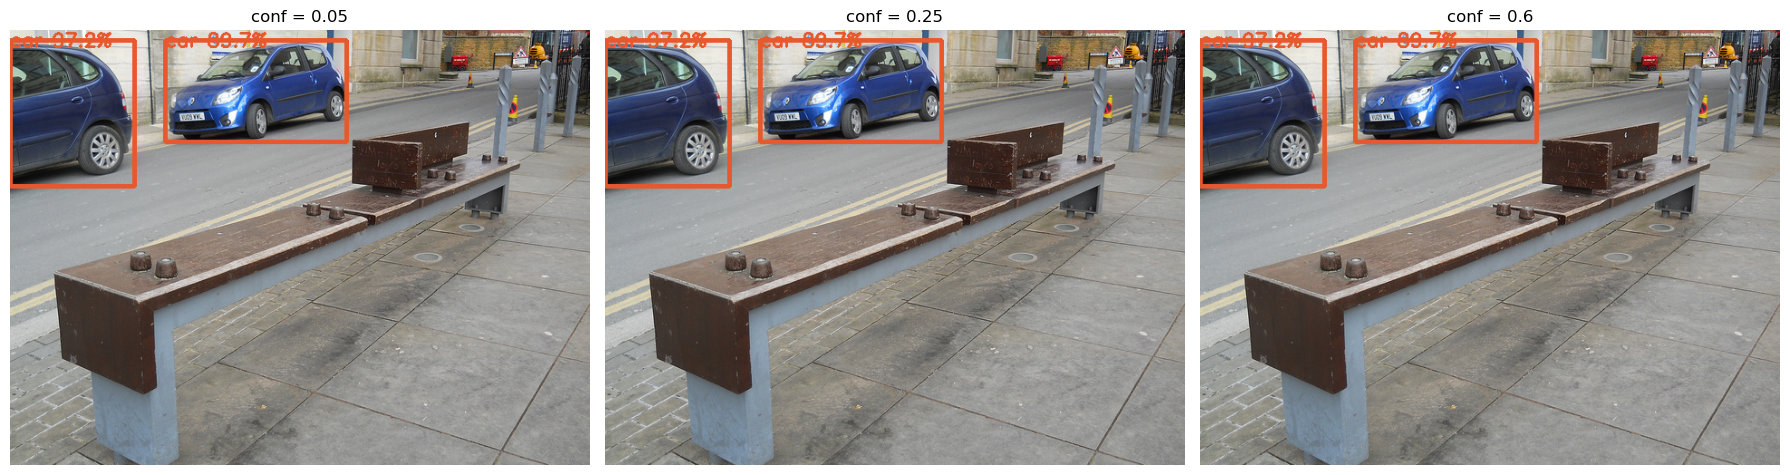

In [4]:
im_src = cv2.imread("web/frontend/samples/car_015.jpg")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, c in zip(ax, [0.05, 0.25, 0.6]):
    a.imshow(draw_rect(im_src, conf=c)); a.set_title(f"conf = {c}"); a.axis("off")
plt.tight_layout(); plt.show()

## 4.4 ทายถูกกี่ภาพ? (ทั้งชุด test)
ภาพแต่ละภาพมีคลาสเดียว (ดูจากชื่อไฟล์ เช่น `car_013.jpg`) → เอาวัตถุที่มั่นใจที่สุดเป็นคำตอบของภาพ แล้วเทียบกับคลาสจริง

In [5]:
rows = []
for mode, model in [("rect", model_rect), ("poly", model_poly)]:
    for f in sorted(Path(f"datasets/yolo_{mode}/test/images").glob("*.jpg")):
        r = model.predict(str(f), imgsz=512, conf=0.25, verbose=False)[0]
        true = f.stem.rsplit("_", 1)[0]
        pred = r.names[int(r.boxes.cls[r.boxes.conf.argmax()])] if len(r.boxes) else "(ไม่เจอ)"
        rows.append({"model": mode, "file": f.name, "true": true, "pred": pred, "correct": true == pred})
df = pd.DataFrame(rows)

summary = df.groupby(["model", "true"])["correct"].agg(["sum", "count"])
summary["accuracy"] = (summary["sum"] / summary["count"] * 100).round(1).astype(str) + "%"
print("ทายถูกทั้งหมด:", {m: f"{g.correct.sum()}/{len(g)} ({g.correct.mean()*100:.1f}%)" for m, g in df.groupby("model")})
summary.rename(columns={"sum": "ถูก", "count": "ทั้งหมด"})

ทายถูกทั้งหมด: {'poly': '55/60 (91.7%)', 'rect': '52/60 (86.7%)'}


ถูก  ทั้งหมด accuracy
model true                             
poly  airplane     15       15   100.0%
      boat         13       15    86.7%
      car          13       15    86.7%
      motorcycle   14       15    93.3%
rect  airplane     15       15   100.0%
      boat         13       15    86.7%
      car          12       15    80.0%
      motorcycle   12       15    80.0%

In [6]:
# ตาราง จริง x ทาย (นับจำนวนภาพ)
for m in ["rect", "poly"]:
    print(m.upper())
    display(pd.crosstab(df[df.model == m]["true"], df[df.model == m]["pred"], rownames=["จริง"], colnames=["ทาย"]))

RECT


ทาย,(ไม่เจอ),airplane,boat,car,motorcycle
จริง,,,,,
airplane,0,15,0,0,0
boat,1,0,13,0,1
car,2,0,1,12,0
motorcycle,3,0,0,0,12


POLY


ทาย,(ไม่เจอ),airplane,boat,car,motorcycle
จริง,,,,,
airplane,0,15,0,0,0
boat,1,0,13,1,0
car,2,0,0,13,0
motorcycle,1,0,0,0,14


In [7]:
# ภาพที่ทายผิด (ถ้ามี)
wrong = df[~df.correct]
print(len(wrong), "ภาพที่ทายผิด")
wrong

13 ภาพที่ทายผิด


,model,file,true,pred,correct
18,rect,boat_042.jpg,boat,motorcycle,False
27,rect,boat_136.jpg,boat,(ไม่เจอ),False
35,rect,car_049.jpg,car,boat,False
43,rect,car_142.jpg,car,(ไม่เจอ),False
44,rect,car_146.jpg,car,(ไม่เจอ),False
53,rect,motorcycle_079.jpg,motorcycle,(ไม่เจอ),False
56,rect,motorcycle_098.jpg,motorcycle,(ไม่เจอ),False
59,rect,motorcycle_121.jpg,motorcycle,(ไม่เจอ),False
78,poly,boat_042.jpg,boat,car,False
87,poly,boat_136.jpg,boat,(ไม่เจอ),False


## 4.5 ลองภาพของเราเอง (ใส่ path ภาพที่หามาเอง)

In [8]:
MY_IMAGE = "my_test.jpg"      # <-- เปลี่ยนเป็นภาพของเรา
if Path(MY_IMAGE).exists():
    im_src = cv2.imread(MY_IMAGE)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].imshow(draw_rect(im_src)); ax[1].imshow(draw_poly(im_src))
    ax[0].axis("off"); ax[1].axis("off"); plt.show()
else:
    print("ยังไม่มีไฟล์", MY_IMAGE, "-> วางภาพไว้ในโฟลเดอร์ final_dip แล้วแก้ชื่อด้านบน")

ยังไม่มีไฟล์ my_test.jpg -> วางภาพไว้ในโฟลเดอร์ final_dip แล้วแก้ชื่อด้านบน


## 4.6 เซฟผล predict ทั้งชุด test (ไว้ส่งอาจารย์) → `runs/predict_rect/`, `runs/predict_poly/`

Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\predict_rect


runs/predict_rect/ : 60 ภาพ


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\predict_poly


runs/predict_poly/ : 60 ภาพ


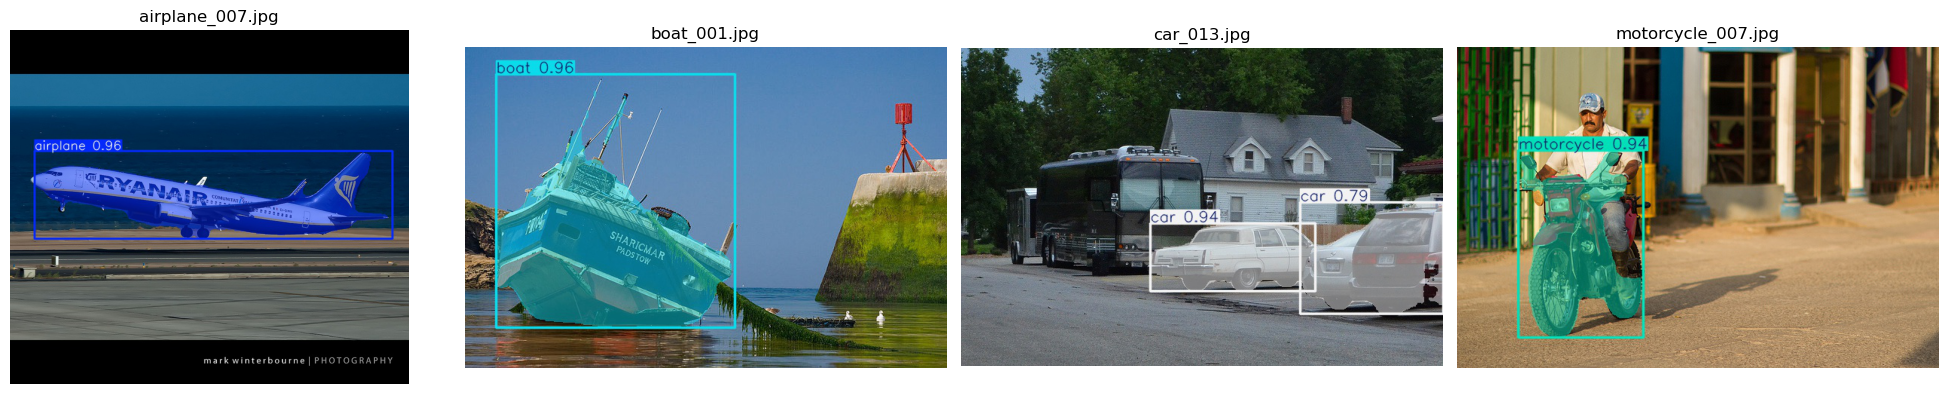

In [9]:
for mode, model in [("rect", model_rect), ("poly", model_poly)]:
    model.predict(source=f"datasets/yolo_{mode}/test/images", imgsz=512, conf=0.25, save=True,
                  project=str(ROOT / "runs"), name=f"predict_{mode}", exist_ok=True, verbose=False)
    print(f"runs/predict_{mode}/ :", len(list(Path(f"runs/predict_{mode}").glob("*.jpg"))), "ภาพ")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, f in zip(ax, sorted(Path("runs/predict_poly").glob("*.jpg"))[::15]):
    a.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); a.set_title(f.name); a.axis("off")
plt.tight_layout(); plt.show()